In [10]:
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [235]:
models = ["tropical", "tropical_v2", "transformer", "edge_transformer", "gnn"]

evaluation_types = ["id_new", "ood_size", "value_ood"]

training_set = "onein_filtered"

dfs = []

for eval_type in evaluation_types:
    
    for model in models:
        
        filename = (f"evaluation_results_{model}_shortest_path_{eval_type}_{training_set}_eval_filtered.csv")
        
        df = pd.read_csv(filename)

        # Add identifiers
        df["model_type"] = model
        df["evaluation_type"] = eval_type
        df["training_set"] = training_set

        dfs.append(df)

# Combine all 25 files
df_all = pd.concat(dfs, ignore_index=True)

In [239]:
models = ["tropical", "tropical_v2", "transformer", "edge_transformer", "gnn"]

evaluation_types = ["id_new", "ood_size", "value_ood"]

training_set = "onein_filtered"

dfs = []

for eval_type in evaluation_types:
    
    for model in models:
        
        filename = (f"evaluation_results_{model}_shortest_path_{eval_type}_{training_set}_eval_unfiltered.csv")
        
        df = pd.read_csv(filename)

        # Add identifiers
        df["model_type"] = model
        df["evaluation_type"] = eval_type
        df["training_set"] = training_set

        dfs.append(df)

# Combine all 25 files
df_all = pd.concat(dfs, ignore_index=True)

In [243]:
models = ["tropical_v2", "transformer", "edge_transformer", "gnn"]

evaluation_types = ["wood", "external"]

training_set = "onein_filtered"

dfs = []

for eval_type in evaluation_types:
    
    for model in models:
        
        filename = (f"evaluation_results_{model}_shortest_path_{eval_type}_{training_set}.csv")
        
        df = pd.read_csv(filename)

        # Add identifiers
        df["model_type"] = model
        df["evaluation_type"] = eval_type
        df["training_set"] = training_set

        dfs.append(df)

# Combine all 25 files
df_all = pd.concat(dfs, ignore_index=True)

In [237]:
df_all.to_csv("evaluation_results_onein_fitered_all.csv", index=False)

In [241]:
df_all.to_csv("evaluation_results_onein_unfiltered_all.csv", index=False)

In [245]:
df_all.to_csv("evaluation_results_onein_filtered_wood_ext.csv", index=False)

In [7]:
pd.set_option('display.max_columns',None)

In [221]:
df_trop = pd.read_csv('training_log_tropical_shortest_path_onein_filtered.csv')
df_trop_v2 = pd.read_csv('training_log_tropical_v2_shortest_path_onein_filtered.csv')
df_trans = pd.read_csv('training_log_transformer_shortest_path_onein_filtered.csv')
df_edge = pd.read_csv('training_log_edge_transformer_shortest_path_onein_filtered.csv')
df_gnn = pd.read_csv('training_log_gnn_shortest_path_onein_filtered.csv')

In [223]:
df_trop["model_type"] = "tropical"
df_trop_v2["model_type"] = "tropical_v2"
df_trans["model_type"] = "transformer"
df_edge["model_type"] = "edge_transformer"
df_gnn["model_type"] = "gnn"

df_all = pd.concat([df_trop, df_trop_v2, df_trans, df_edge, df_gnn], ignore_index=True)

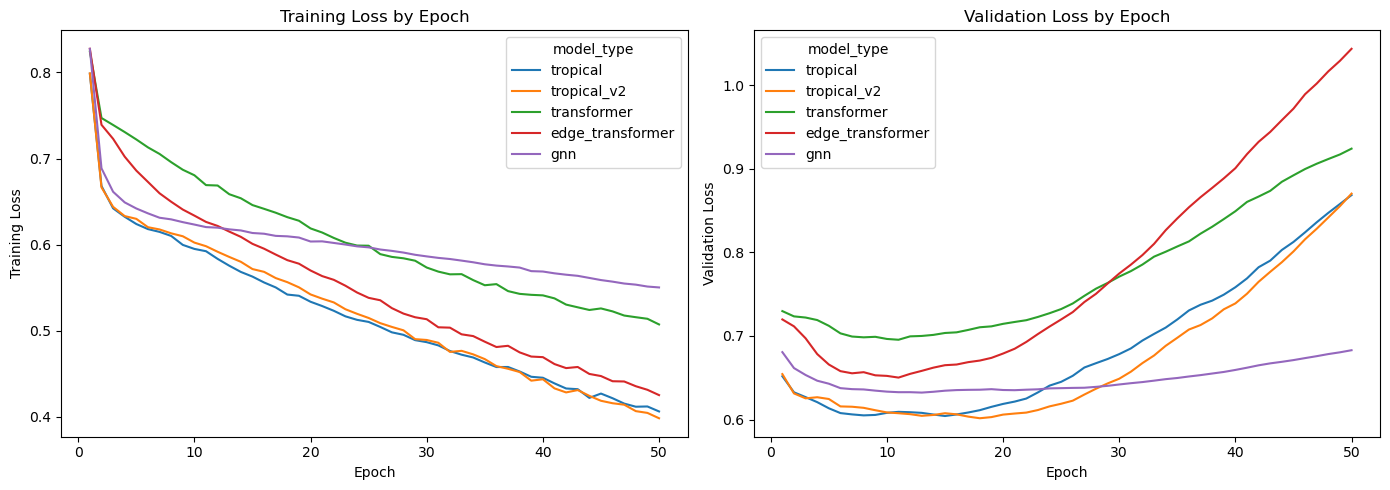

In [225]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

sns.lineplot(
    data=df_all,
    x="epoch",
    y="train_loss",
    hue="model_type",
    ax=axes[0]
)

axes[0].set_title("Training Loss by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training Loss")

sns.lineplot(
    data=df_all,
    x="epoch",
    y="val_loss",
    hue="model_type",
    ax=axes[1]
)

axes[1].set_title("Validation Loss by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Loss")

plt.tight_layout()
plt.show()

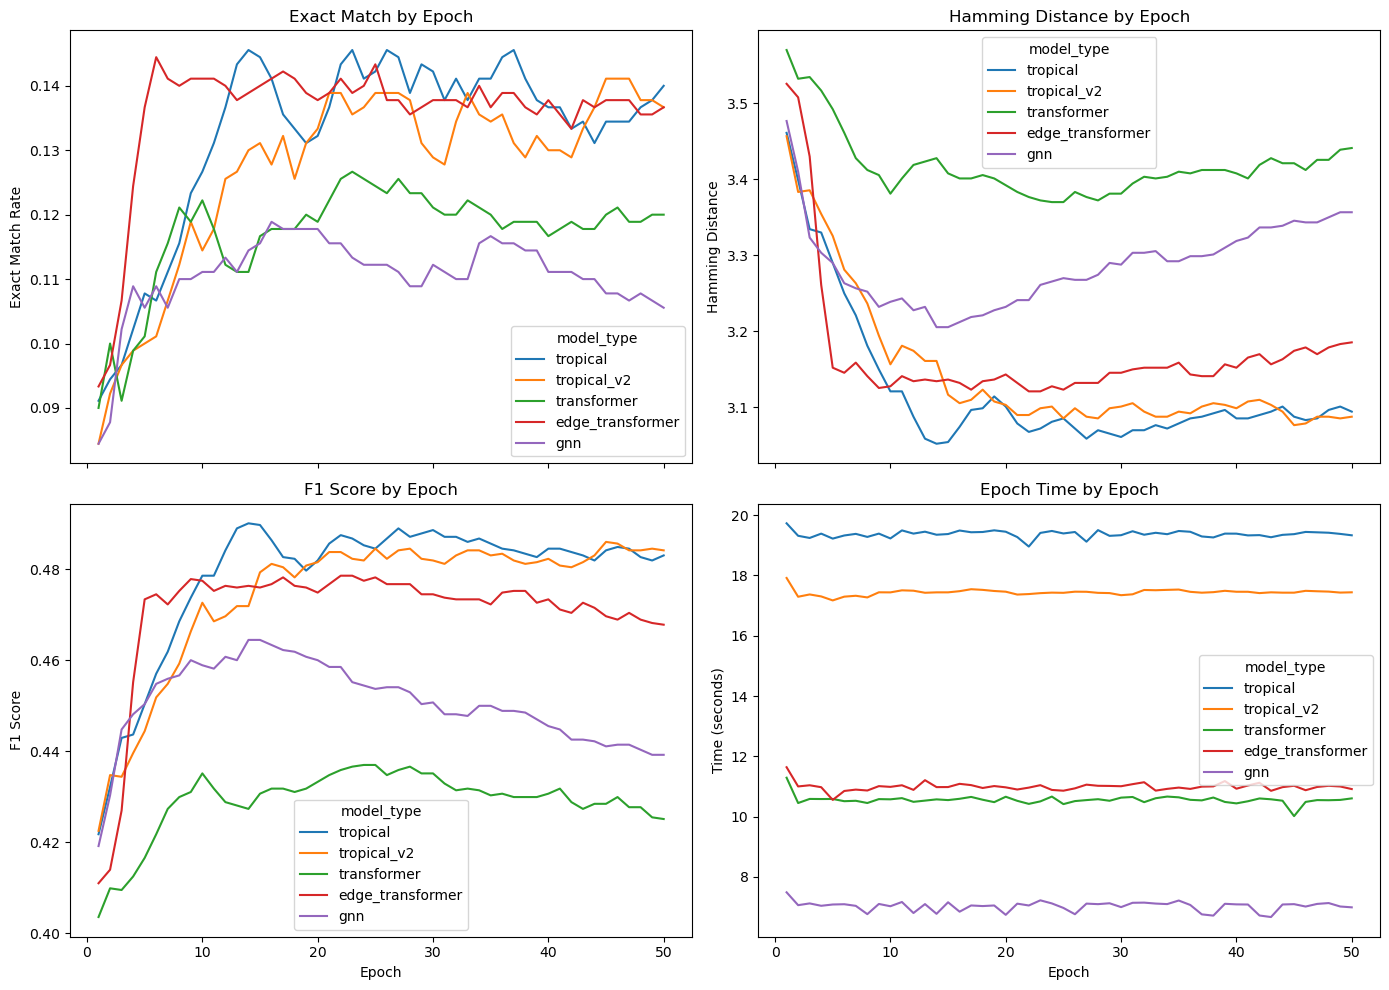

In [227]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)

sns.lineplot(
    data=df_all,
    x="epoch",
    y="exact_match",
    hue="model_type",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Exact Match by Epoch")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Exact Match Rate")

sns.lineplot(
    data=df_all,
    x="epoch",
    y="hamming",
    hue="model_type",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Hamming Distance by Epoch")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Hamming Distance")

sns.lineplot(
    data=df_all,
    x="epoch",
    y="f1",
    hue="model_type",
    ax=axes[1, 0]
)
axes[1, 0].set_title("F1 Score by Epoch")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("F1 Score")

sns.lineplot(
    data=df_all,
    x="epoch",
    y="epoch_time_seconds",
    hue="model_type",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Epoch Time by Epoch")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Time (seconds)")

plt.tight_layout()
plt.show()

## Filtered ID Evaluation Results

In [247]:
df_tropical_eval = pd.read_csv('evaluation_results_tropical_shortest_path_id_new_onein_filtered_eval_filtered.csv')
df_tropical_v2_eval = pd.read_csv('evaluation_results_tropical_v2_shortest_path_id_new_onein_filtered_eval_filtered.csv')
df_transformer_eval = pd.read_csv('evaluation_results_transformer_shortest_path_id_new_onein_filtered_eval_filtered.csv')
df_edge_eval = pd.read_csv('evaluation_results_edge_transformer_shortest_path_id_new_onein_filtered_eval_filtered.csv')
df_gnn_eval = pd.read_csv('evaluation_results_gnn_shortest_path_id_new_onein_filtered_eval_filtered.csv')

## Filtered ID Unfiltered Evaluation Results

In [262]:
df_tropical_eval = pd.read_csv('evaluation_results_tropical_shortest_path_id_new_onein_filtered_eval_unfiltered.csv')
df_tropical_v2_eval = pd.read_csv('evaluation_results_tropical_v2_shortest_path_id_new_onein_filtered_eval_unfiltered.csv')
df_transformer_eval = pd.read_csv('evaluation_results_transformer_shortest_path_id_new_onein_filtered_eval_unfiltered.csv')
df_edge_eval = pd.read_csv('evaluation_results_edge_transformer_shortest_path_id_new_onein_filtered_eval_unfiltered.csv')
df_gnn_eval = pd.read_csv('evaluation_results_gnn_shortest_path_id_new_onein_filtered_eval_filtered.csv')

## Filtered OOD Size Evaluation Results

In [276]:
df_tropical_eval = pd.read_csv('evaluation_results_tropical_shortest_path_ood_size_onein_filtered_eval_filtered.csv')
df_tropical_v2_eval = pd.read_csv('evaluation_results_tropical_v2_shortest_path_ood_size_onein_filtered_eval_filtered.csv')
df_transformer_eval = pd.read_csv('evaluation_results_transformer_shortest_path_ood_size_onein_filtered_eval_filtered.csv')
df_edge_eval = pd.read_csv('evaluation_results_edge_transformer_shortest_path_ood_size_onein_filtered_eval_filtered.csv')
df_gnn_eval = pd.read_csv('evaluation_results_gnn_shortest_path_ood_size_onein_filtered_eval_filtered.csv')

## Filtered OOD Size Unfiltered Evaluation Results

In [290]:
df_tropical_eval = pd.read_csv('evaluation_results_tropical_shortest_path_ood_size_onein_filtered_eval_unfiltered.csv')
df_tropical_v2_eval = pd.read_csv('evaluation_results_tropical_v2_shortest_path_ood_size_onein_filtered_eval_unfiltered.csv')
df_transformer_eval = pd.read_csv('evaluation_results_transformer_shortest_path_ood_size_onein_filtered_eval_unfiltered.csv')
df_edge_eval = pd.read_csv('evaluation_results_edge_transformer_shortest_path_ood_size_onein_filtered_eval_unfiltered.csv')
df_gnn_eval = pd.read_csv('evaluation_results_gnn_shortest_path_ood_size_onein_filtered_eval_unfiltered.csv')

## Filtered OOD Value Evaluation Results

In [304]:
df_tropical_eval = pd.read_csv('evaluation_results_tropical_shortest_path_value_ood_onein_filtered_eval_filtered.csv')
df_tropical_v2_eval = pd.read_csv('evaluation_results_tropical_v2_shortest_path_value_ood_onein_filtered_eval_filtered.csv')
df_transformer_eval = pd.read_csv('evaluation_results_transformer_shortest_path_value_ood_onein_filtered_eval_filtered.csv')
df_edge_eval = pd.read_csv('evaluation_results_edge_transformer_shortest_path_value_ood_onein_filtered_eval_filtered.csv')
df_gnn_eval = pd.read_csv('evaluation_results_gnn_shortest_path_value_ood_onein_filtered_eval_filtered.csv')

## Filtered OOD Value Unfiltered Evaluation Results

In [318]:
df_tropical_eval = pd.read_csv('evaluation_results_tropical_shortest_path_value_ood_onein_filtered_eval_unfiltered.csv')
df_tropical_v2_eval = pd.read_csv('evaluation_results_tropical_v2_shortest_path_value_ood_onein_filtered_eval_unfiltered.csv')
df_transformer_eval = pd.read_csv('evaluation_results_transformer_shortest_path_value_ood_onein_filtered_eval_unfiltered.csv')
df_edge_eval = pd.read_csv('evaluation_results_edge_transformer_shortest_path_value_ood_onein_filtered_eval_unfiltered.csv')
df_gnn_eval = pd.read_csv('evaluation_results_gnn_shortest_path_value_ood_onein_filtered_eval_unfiltered.csv')

## Wood Evaluation Results

In [374]:
df_tropical_eval = pd.read_csv('evaluation_results_tropical_shortest_path_wood_onein_filtered.csv')
df_tropical_v2_eval = pd.read_csv('evaluation_results_tropical_v2_shortest_path_wood_onein_filtered.csv')
df_transformer_eval = pd.read_csv('evaluation_results_transformer_shortest_path_wood_onein_filtered.csv')
df_edge_eval = pd.read_csv('evaluation_results_edge_transformer_shortest_path_wood_onein_filtered.csv')
df_gnn_eval = pd.read_csv('evaluation_results_gnn_shortest_path_wood_onein_filtered.csv')

## External Evaluation Results

In [382]:
#df_tropical_eval = pd.read_csv('evaluation_results_tropical_shortest_path_external_onein_filtered.csv')
df_tropical_v2_eval = pd.read_csv('evaluation_results_tropical_v2_shortest_path_external_onein_filtered.csv')
df_transformer_eval = pd.read_csv('evaluation_results_transformer_shortest_path_external_onein_filtered.csv')
df_edge_eval = pd.read_csv('evaluation_results_edge_transformer_shortest_path_external_onein_filtered.csv')
df_gnn_eval = pd.read_csv('evaluation_results_gnn_shortest_path_external_onein_filtered.csv')

In [384]:
df_tropical_eval["model_type"] = "tropical"
df_tropical_v2_eval["model_type"] = "tropical_v2"
df_transformer_eval["model_type"] = "transformer"
df_gnn_eval["model_type"] = "gnn"
df_edge_eval["model_type"] = "edge_transformer"


df_all_eval = pd.concat([df_gnn_eval, df_edge_eval, df_tropical_v2_eval],ignore_index=True)

df_all_eval.head()

,model_type,problem_type,eval_mode,wood_problem,wood_rows,wood_cols,network_name,graph_seed,n_nodes,n_edges,...,inference_time,candidate_objective,candidate_objective_gap,candidate_pool_size,num_candidates,candidate_search_time,hybrid_total_time,candidate_exact_match,candidate_hamming_distance,candidate_correct_edges
0,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,...,0.154422,694.054024,0.121426,5,5,0.042088,0.196510,0,2,0
1,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,...,0.002173,184.159473,0.342484,5,5,0.025946,0.028119,0,2,0
2,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,...,0.002000,159.905843,0.374953,5,5,0.025122,0.027122,0,2,0
3,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,...,0.001925,160.656519,0.373856,5,5,0.026019,0.027944,0,2,0
4,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,...,0.002341,803.250811,0.106680,5,5,0.031280,0.033621,0,2,0


In [386]:
summary = (
    df_all_eval.groupby(["model_type", "density"])
    .agg(
        count=("objective_gap", "count"),

        # Direct model prediction
        objective_gap_avg=("objective_gap", "mean"),
        objective_gap_median=("objective_gap", "median"),
        objective_gap_std=("objective_gap", "std"),

        candidate_objective_gap_avg=("candidate_objective_gap", "mean"),
        candidate_objective_gap_median=("candidate_objective_gap", "median"),
        candidate_objective_gap_std=("candidate_objective_gap", "std"),
        exact_match_avg=("exact_match", "mean"),
        exact_match_std=("exact_match", "std"),

        candidate_exact_match_avg=("candidate_exact_match", "mean"),
        candidate_exact_match_std=("candidate_exact_match", "std"),

        hamming_distance_avg=("hamming_distance", "mean"),
        hamming_distance_std=("hamming_distance", "std"),

        candidate_hamming_distance_avg=("candidate_hamming_distance", "mean"),
        candidate_hamming_distance_std=("candidate_hamming_distance", "std"),

        inference_time_avg=("inference_time", "mean"),
        inference_time_std=("inference_time", "std"),

        hybrid_total_time_avg=("hybrid_total_time", "mean"),
        hybrid_total_time_std=("hybrid_total_time", "std"),

        mip_solve_time_avg=("mip_solve_time", "mean"),
        mip_solve_time_std=("mip_solve_time", "std"),

        candidate_correct_edges_avg=("candidate_correct_edges", "mean"),
        candidate_correct_edges_std=("candidate_correct_edges", "std"),

        candidate_search_time_avg=("candidate_search_time", "mean"),
        candidate_search_time_std=("candidate_search_time", "std"),

        candidate_pool_size_avg=("candidate_pool_size", "mean"),
        num_candidates_avg=("num_candidates", "mean"),


    )
    .reset_index()
)

summary

,model_type,density,count,objective_gap_avg,objective_gap_median,objective_gap_std,candidate_objective_gap_avg,candidate_objective_gap_median,candidate_objective_gap_std,exact_match_avg,...,hybrid_total_time_avg,hybrid_total_time_std,mip_solve_time_avg,mip_solve_time_std,candidate_correct_edges_avg,candidate_correct_edges_std,candidate_search_time_avg,candidate_search_time_std,candidate_pool_size_avg,num_candidates_avg
0,edge_transformer,1.681682,150,0.645459,0.657723,0.152150,0.509200,0.542588,0.206166,0.006667,...,0.062713,0.063856,0.298333,0.270965,0.486667,0.564458,0.060842,0.063890,7.0,50.2
1,edge_transformer,2.329082,150,0.213620,0.205901,0.140573,0.198825,0.198318,0.145196,0.080000,...,1.550641,1.249730,57.437704,76.811588,0.753333,0.759165,1.446549,1.249761,7.0,50.2
2,edge_transformer,3.083491,150,0.440064,0.446191,0.196433,0.435293,0.445232,0.195643,0.000000,...,0.319157,0.278026,5.046546,5.700139,0.013333,0.115082,0.307562,0.278701,7.0,50.2
3,gnn,1.681682,150,0.618391,0.669870,0.216690,0.587721,0.646437,0.222640,0.026667,...,0.064516,0.069667,0.303187,0.286110,0.253333,0.569784,0.063396,0.069695,7.0,50.2
4,gnn,2.329082,150,0.202872,0.201915,0.131414,0.135081,0.132992,0.113258,0.086667,...,1.466792,1.234056,57.145201,75.860456,0.980000,0.958676,1.449494,1.234078,7.0,50.2
5,gnn,3.083491,150,0.440334,0.446191,0.196107,0.440334,0.446191,0.196107,0.000000,...,0.316003,0.280756,5.136271,5.805756,0.000000,0.000000,0.312938,0.281468,7.0,50.2
6,tropical_v2,1.681682,150,0.621709,0.659948,0.205900,0.587109,0.612236,0.221551,0.013333,...,0.067599,0.069743,0.307406,0.286665,0.140000,0.384777,0.061811,0.069774,7.0,50.2
7,tropical_v2,2.329082,150,0.223232,0.212746,0.149960,0.171795,0.189476,0.125056,0.060000,...,1.851767,1.248915,57.362647,76.828481,0.873333,0.861532,1.429434,1.248630,7.0,50.2
8,tropical_v2,3.083491,150,0.439499,0.446191,0.197227,0.438897,0.446191,0.198229,0.000000,...,0.356653,0.275699,5.099643,5.695569,0.000000,0.000000,0.313737,0.275366,7.0,50.2


In [380]:
summary = (
    df_all_eval.groupby(["model_type", "attack_limit"])
    .agg(
        count=("objective_gap", "count"),

        # Direct model prediction
        objective_gap_avg=("objective_gap", "mean"),
        objective_gap_median=("objective_gap", "median"),
        objective_gap_std=("objective_gap", "std"),

        candidate_objective_gap_avg=("candidate_objective_gap", "mean"),
        candidate_objective_gap_median=("candidate_objective_gap", "median"),
        candidate_objective_gap_std=("candidate_objective_gap", "std"),
        
        #exact_match_avg=("exact_match", "mean"),
        #exact_match_std=("exact_match", "std"),

        #candidate_exact_match_avg=("candidate_exact_match", "mean"),
        #candidate_exact_match_std=("candidate_exact_match", "std"),

        hamming_distance_avg=("hamming_distance", "mean"),
        hamming_distance_std=("hamming_distance", "std"),

        candidate_hamming_distance_avg=("candidate_hamming_distance", "mean"),
        candidate_hamming_distance_std=("candidate_hamming_distance", "std"),

        inference_time_avg=("inference_time", "mean"),
        inference_time_std=("inference_time", "std"),

        hybrid_total_time_avg=("hybrid_total_time", "mean"),
        hybrid_total_time_std=("hybrid_total_time", "std"),

        mip_solve_time_avg=("mip_solve_time", "mean"),
        mip_solve_time_std=("mip_solve_time", "std"),

        #candidate_correct_edges_avg=("candidate_correct_edges", "mean"),
        #candidate_correct_edges_std=("candidate_correct_edges", "std"),

        #candidate_search_time_avg=("candidate_search_time", "mean"),
        #candidate_search_time_std=("candidate_search_time", "std"),

        #candidate_pool_size_avg=("candidate_pool_size", "mean"),
        #num_candidates_avg=("num_candidates", "mean"),


    )
    .reset_index()
)

summary

,model_type,attack_limit,count,objective_gap_avg,objective_gap_median,objective_gap_std,candidate_objective_gap_avg,candidate_objective_gap_median,candidate_objective_gap_std,hamming_distance_avg,hamming_distance_std,candidate_hamming_distance_avg,candidate_hamming_distance_std,inference_time_avg,inference_time_std,hybrid_total_time_avg,hybrid_total_time_std,mip_solve_time_avg,mip_solve_time_std
0,edge_transformer,5,120,0.270285,0.255435,0.094268,0.250235,0.235294,0.095131,9.541667,0.924874,9.375000,1.085136,0.003355,0.015047,0.068071,0.037261,1.276599,0.925261
1,edge_transformer,10,120,0.348393,0.347826,0.081260,0.340796,0.346327,0.083295,17.450000,2.153168,17.400000,2.193957,0.001974,0.000174,0.501368,0.251433,4.385256,7.713439
2,gnn,5,120,0.243121,0.234314,0.097462,0.215182,0.200000,0.099248,9.325000,1.175110,9.141667,1.197307,0.002575,0.015623,0.068049,0.037815,1.277100,0.926200
3,gnn,10,120,0.292016,0.278889,0.082551,0.284508,0.270979,0.084244,17.516667,2.184681,17.516667,2.184681,0.001140,0.000105,0.507371,0.252388,4.371492,7.673024
4,tropical_v2,5,120,0.222834,0.210526,0.093800,0.186026,0.176471,0.082881,9.025000,1.386989,8.858333,1.379903,0.012120,0.067683,0.077551,0.075116,1.315281,0.947082
5,tropical_v2,10,120,0.288278,0.272727,0.084713,0.281148,0.263158,0.085095,17.500000,2.219092,17.466667,2.211252,0.005927,0.000984,0.515289,0.256432,4.500992,7.909818


In [352]:
def add_confidence_intervals(summary, metrics, confidence_multiplier=1.96):

    for metric in metrics:
        mean_col = f"{metric}_avg"
        std_col = f"{metric}_std"

        summary[f"{metric}_se"] = (summary[std_col] / np.sqrt(summary["count"]))

        summary[f"{metric}_ci_lower"] = (summary[mean_col] - confidence_multiplier * summary[f"{metric}_se"])

        summary[f"{metric}_ci_upper"] = (summary[mean_col] + confidence_multiplier * summary[f"{metric}_se"])

    return summary

In [354]:
def plot_metrics_with_ci(summary):

    metrics = [
        ("objective_gap",
         "Average Objective Gap",
         "Direct Prediction: Objective Gap"),

        ("inference_time",
         "Average Inference Time (s)",
         "Direct Prediction: Inference Time"),

        ("candidate_objective_gap",
         "Average Objective Gap",
         "Candidate Search: Objective Gap"),

        ("hybrid_total_time",
         "Average Total Time (s)",
         "Candidate Search: Total Time")]

    fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)

    axes = axes.flatten()

    for ax, (metric, ylabel, title) in zip(axes, metrics):

        for model, group in summary.groupby("model_type"):

            group = group.sort_values("density")

            line, = ax.plot(group["density"], group[f"{metric}_avg"], marker="o", label=model)

            # shaded 95% confidence interval
            ax.fill_between(group["density"],group[f"{metric}_ci_lower"],group[f"{metric}_ci_upper"],color=line.get_color(),alpha=0.15)

        ax.set_title(title)
        ax.set_xlabel("Arc-to-Node Ratio (m/n)")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)

    # one shared legend
    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(handles, labels, title="Model", loc="lower center", ncol=len(labels), bbox_to_anchor=(0.5, 1.02))

    plt.tight_layout()
    plt.show()

In [356]:
# metrics that need confidence intervals
metrics_for_ci = ["objective_gap", "inference_time", "candidate_objective_gap", "hybrid_total_time"]

# calculate confidence intervals
summary = add_confidence_intervals(summary, metrics_for_ci)

## Filtered ID Filtered Evaluation

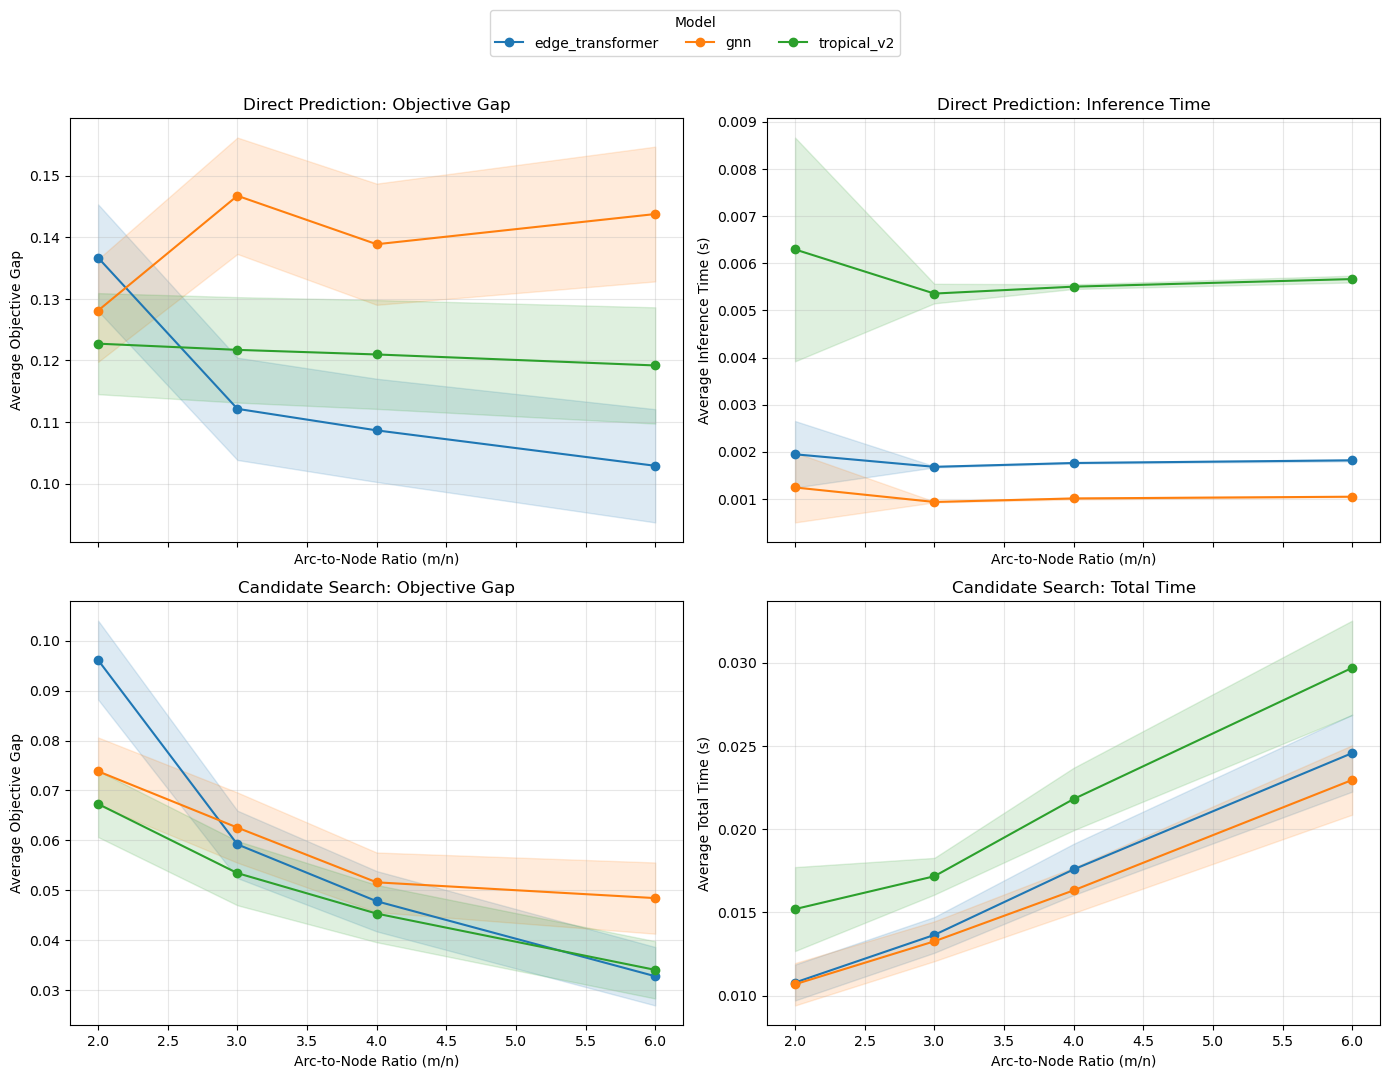

In [260]:
# create plots
plot_metrics_with_ci(summary)

## Filtered ID Unfiltered Evaluation

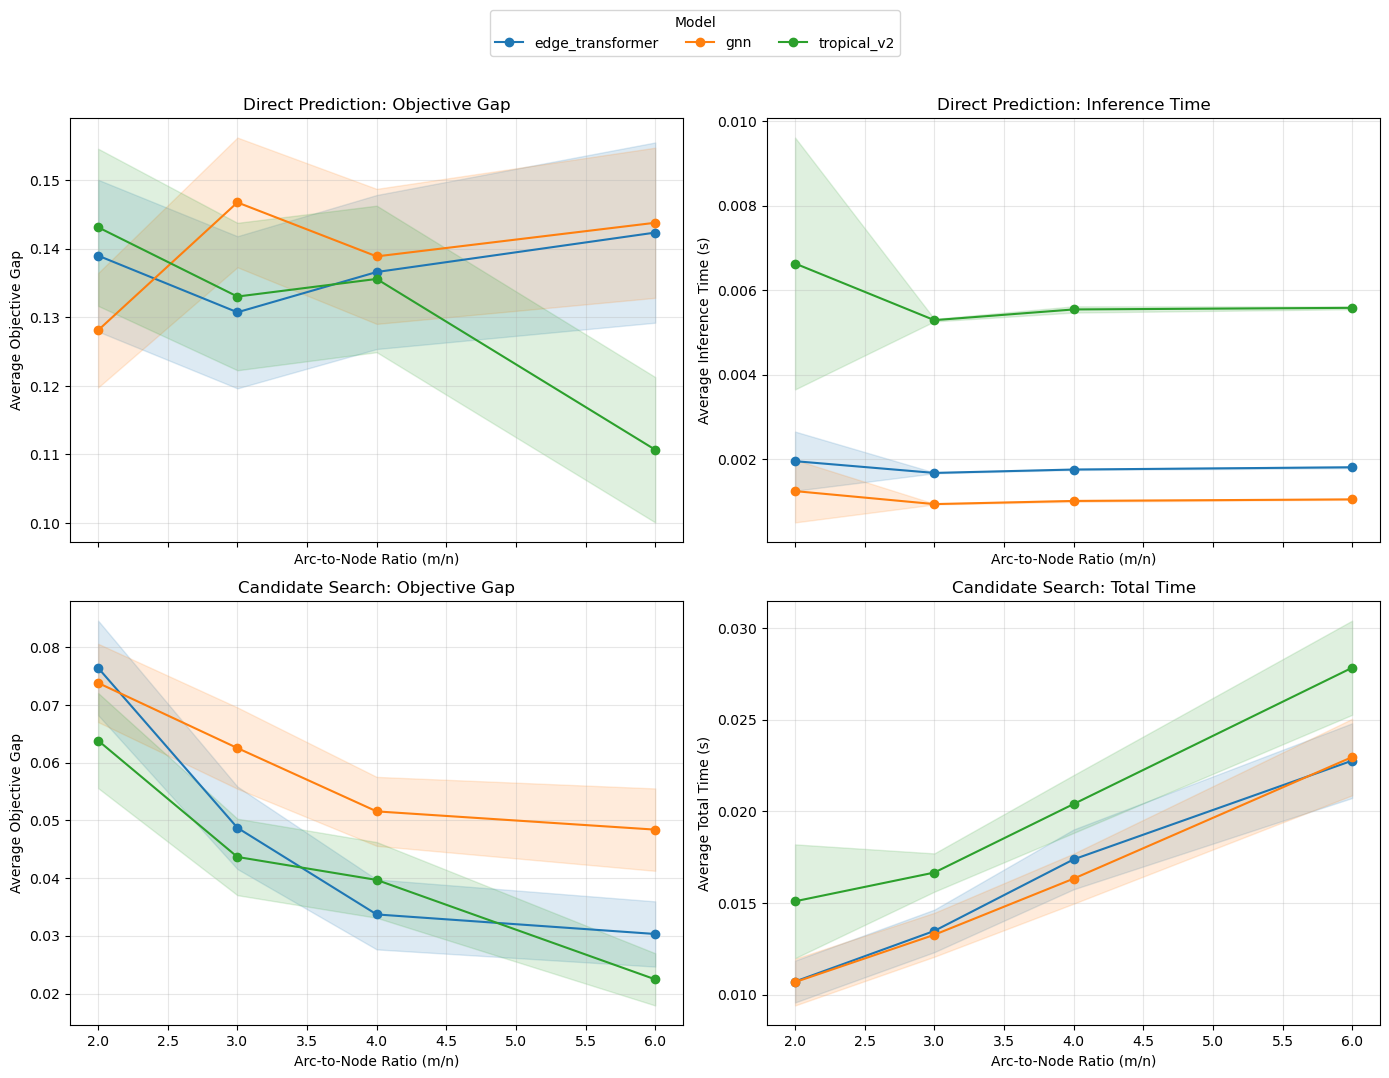

In [274]:
plot_metrics_with_ci(summary)

## Filtered OOD Size Filtered Evaluation

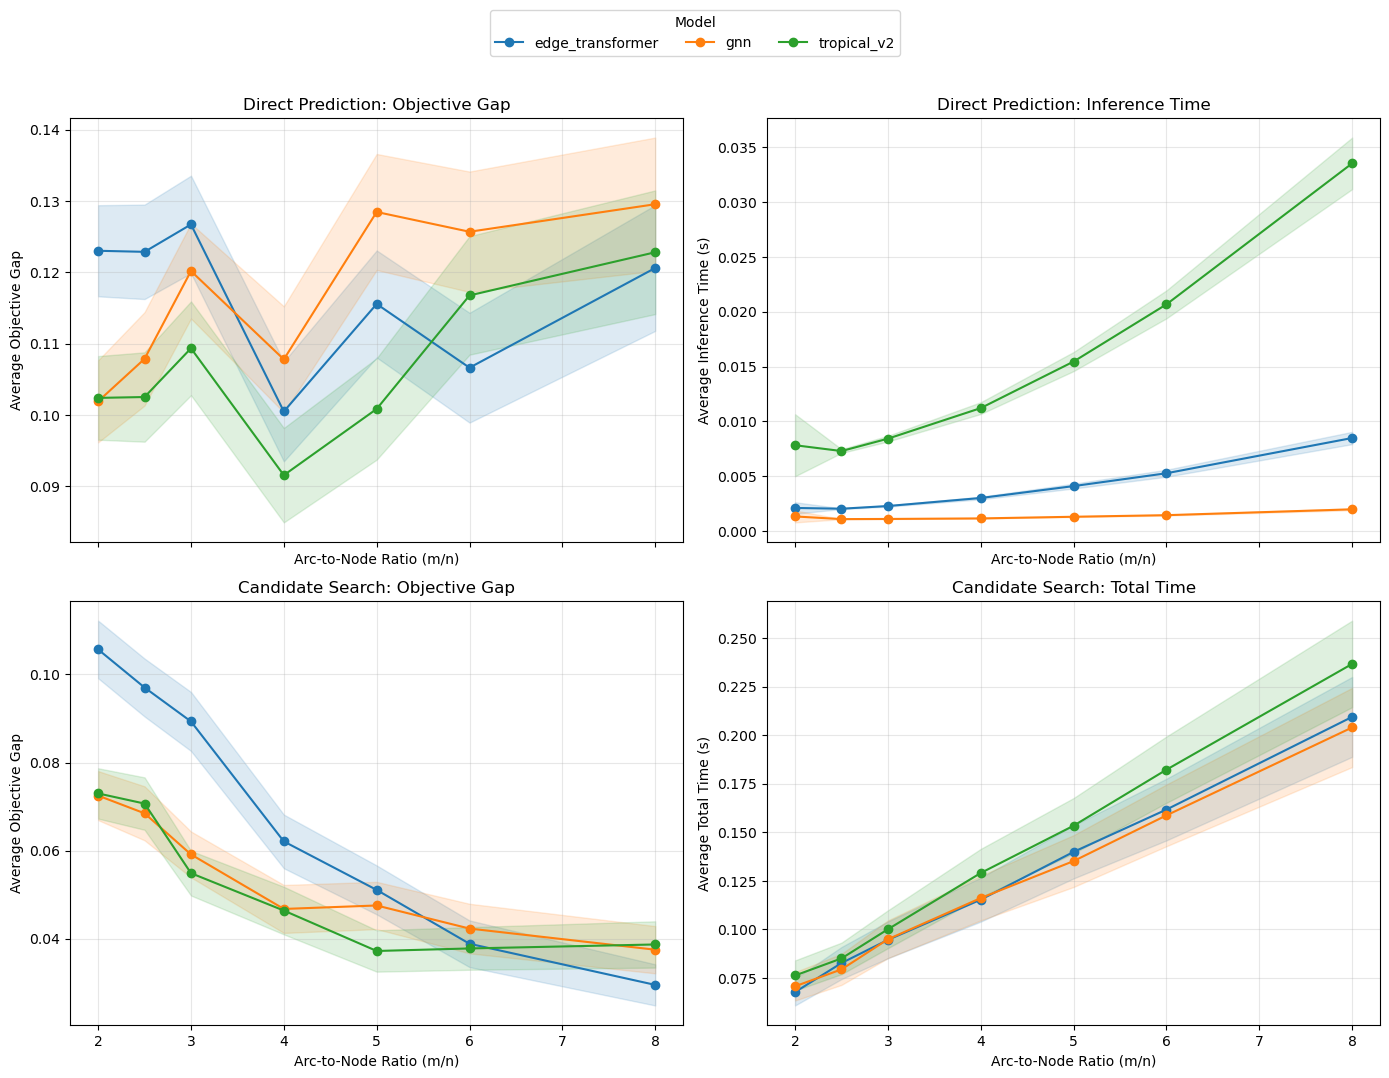

In [288]:
plot_metrics_with_ci(summary)

## Filtered OOD Size Uniltered Evaluation

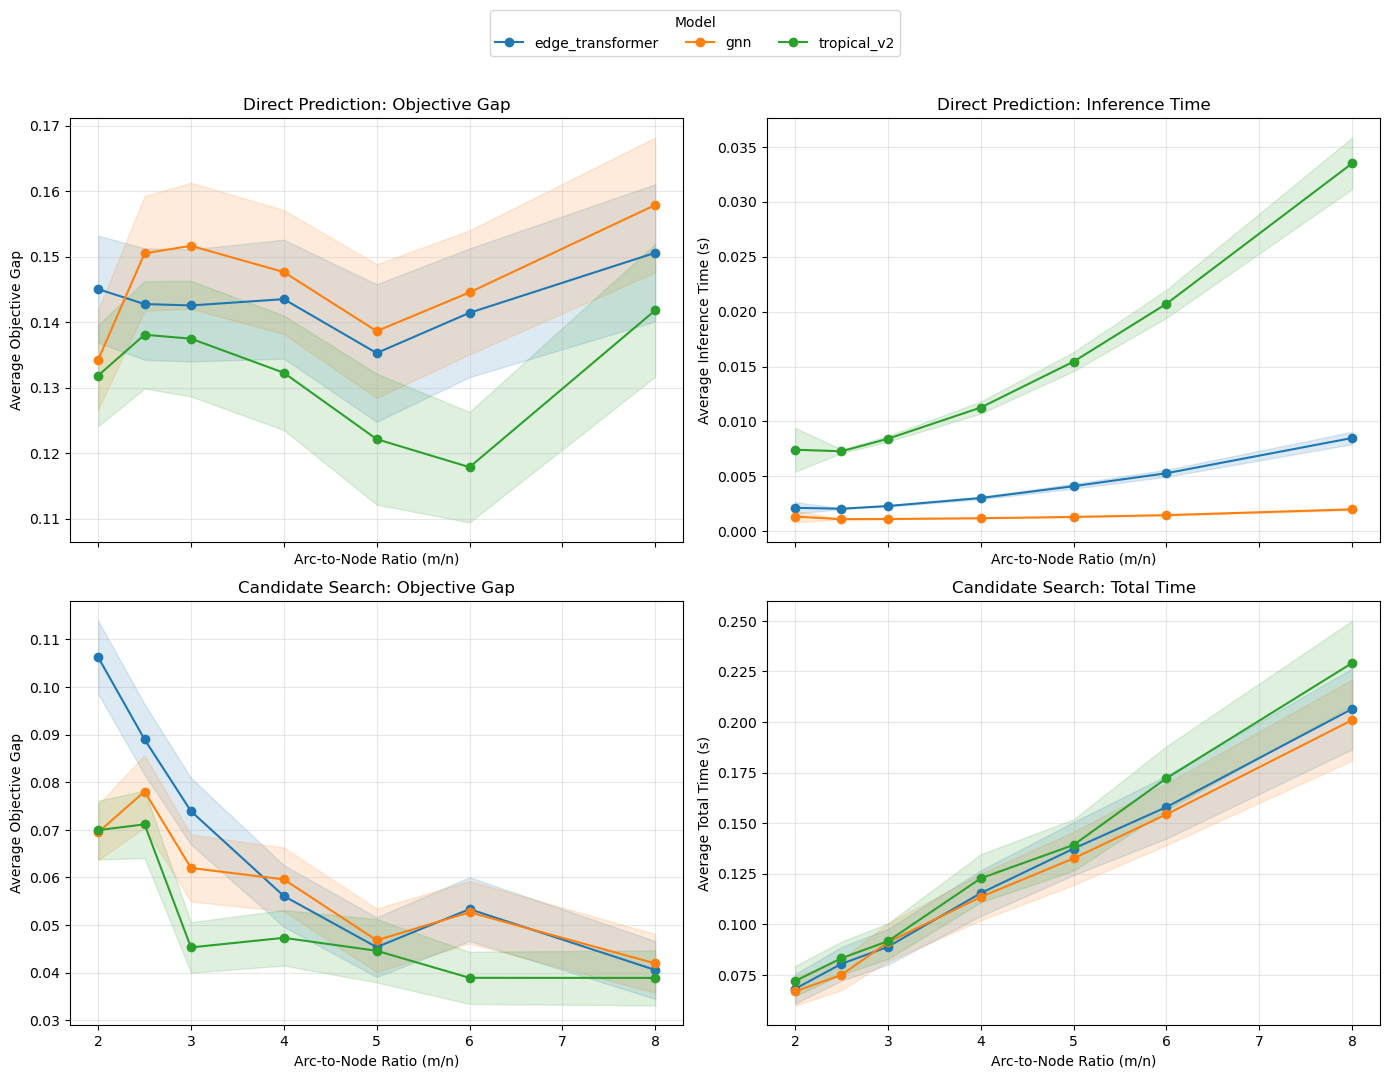

In [302]:
plot_metrics_with_ci(summary)

## Filtered OOD Value Filtered Evaluation

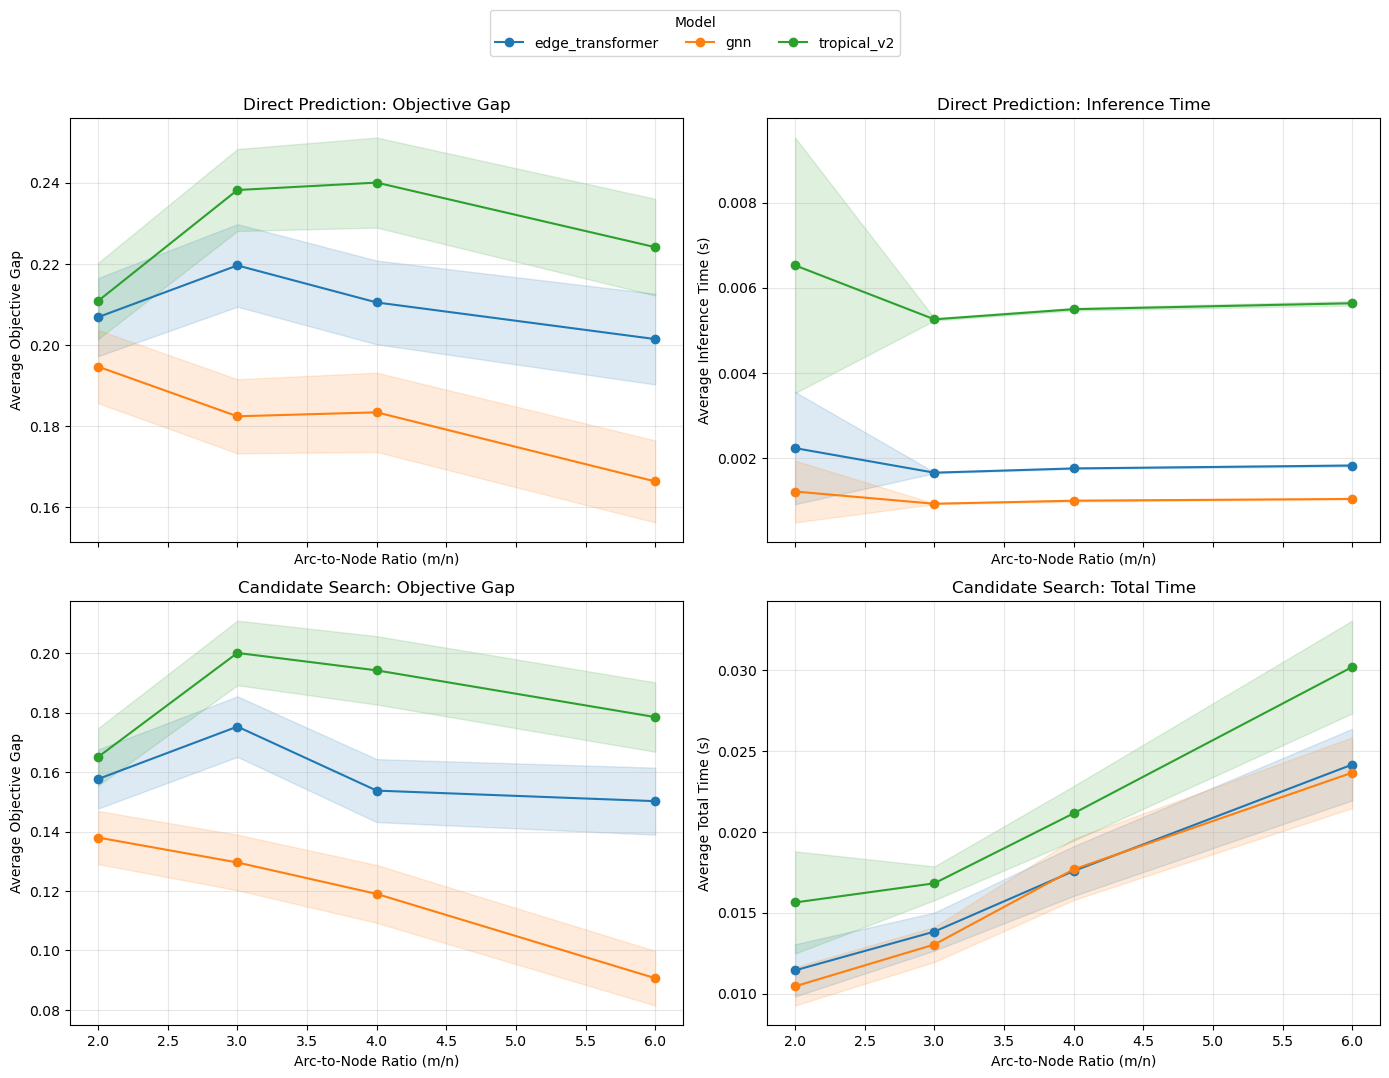

In [316]:
plot_metrics_with_ci(summary)

## Filtered OOD Value Unfiltered Evaluation

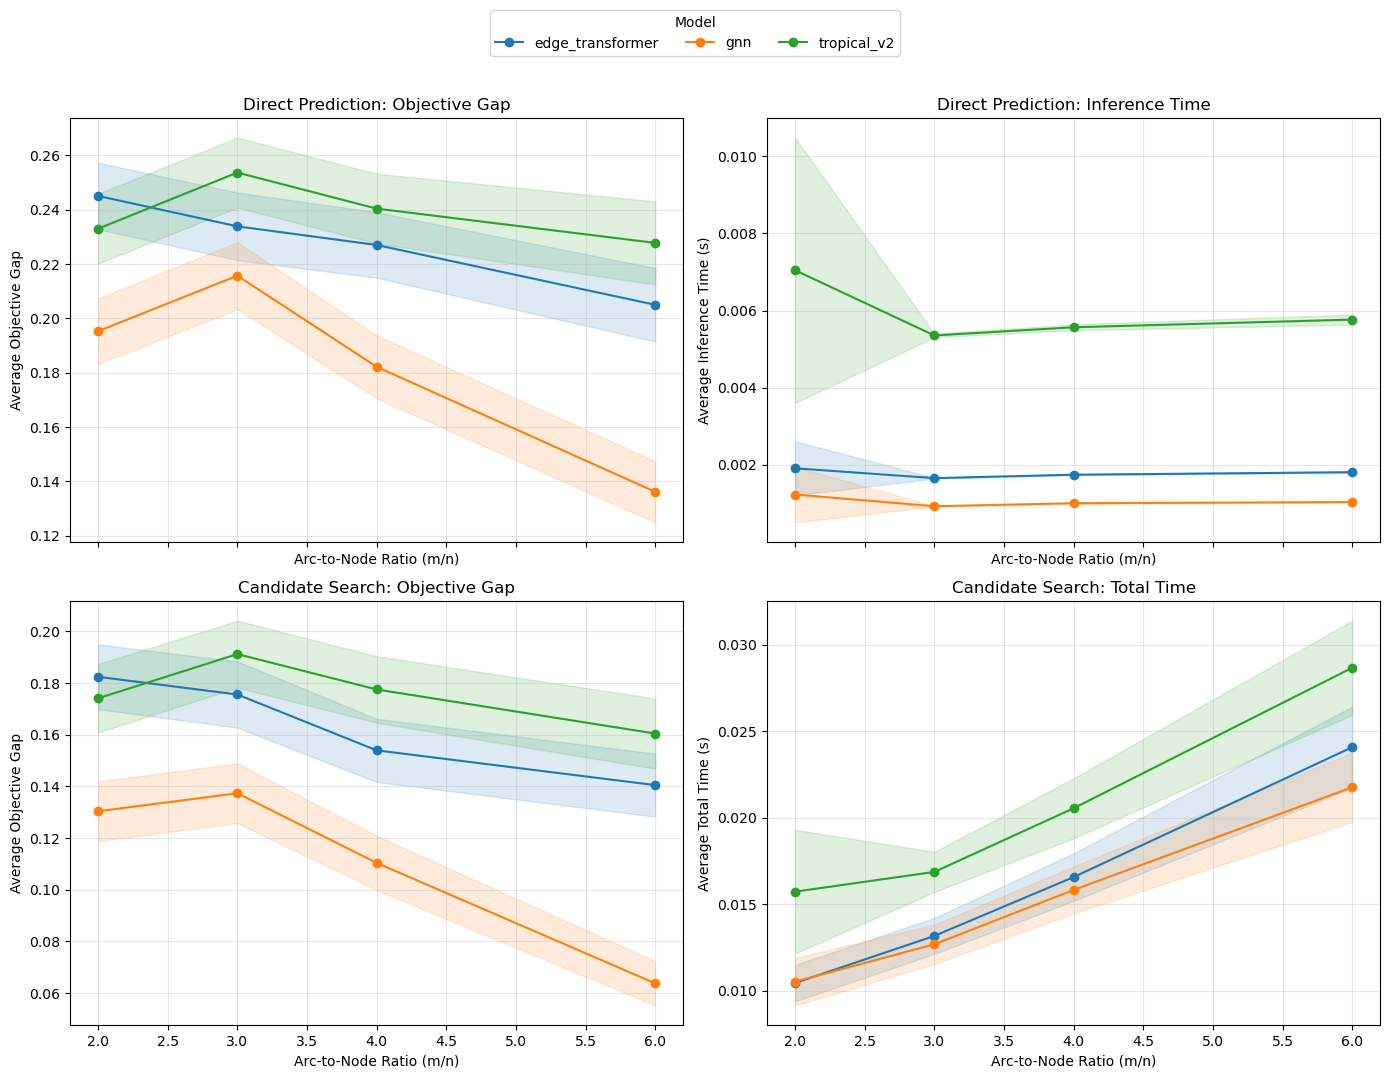

In [330]:
plot_metrics_with_ci(summary)

## Wood Evaluation

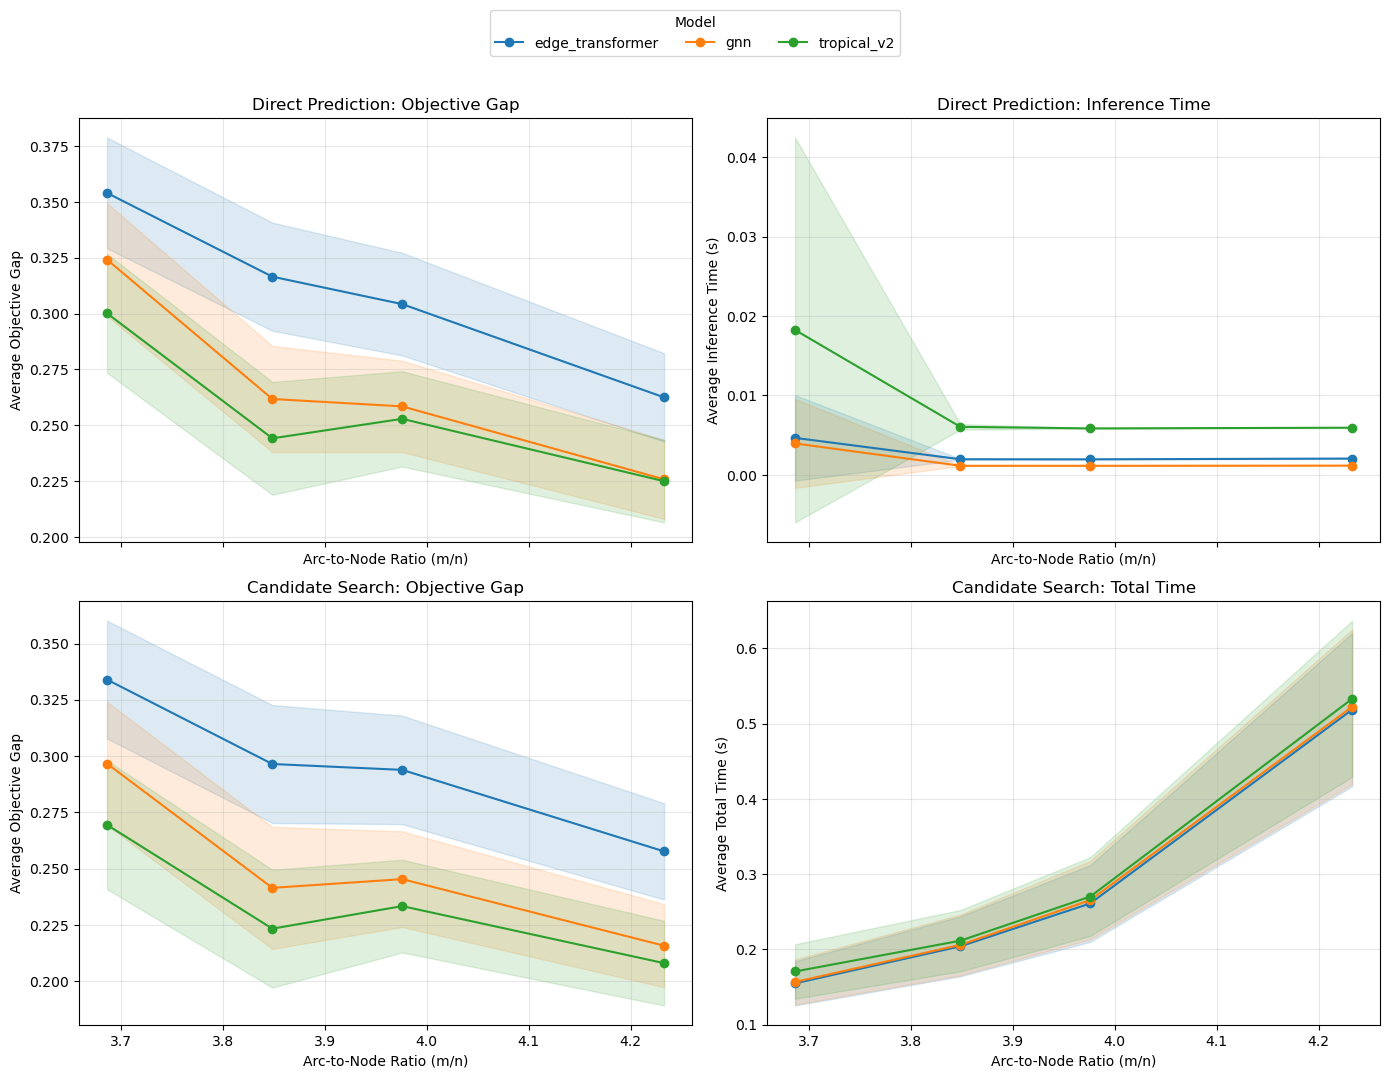

In [344]:
plot_metrics_with_ci(summary)

## External Evaluation

In [358]:
df_all_eval.head()

,model_type,problem_type,eval_mode,wood_problem,wood_rows,wood_cols,network_name,graph_seed,n_nodes,n_edges,...,inference_time,candidate_objective,candidate_objective_gap,candidate_pool_size,num_candidates,candidate_search_time,hybrid_total_time,candidate_exact_match,candidate_hamming_distance,candidate_correct_edges
0,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,...,0.154422,694.054024,0.121426,5,5,0.042088,0.196510,0,2,0
1,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,...,0.002173,184.159473,0.342484,5,5,0.025946,0.028119,0,2,0
2,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,...,0.002000,159.905843,0.374953,5,5,0.025122,0.027122,0,2,0
3,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,...,0.001925,160.656519,0.373856,5,5,0.026019,0.027944,0,2,0
4,gnn,shortest_path,external,NaN,NaN,NaN,rail_road_transportation_network,NaN,1054,3250,...,0.002341,803.250811,0.106680,5,5,0.031280,0.033621,0,2,0


In [360]:
df_all_eval.tail()

,model_type,problem_type,eval_mode,wood_problem,wood_rows,wood_cols,network_name,graph_seed,n_nodes,n_edges,...,inference_time,candidate_objective,candidate_objective_gap,candidate_pool_size,num_candidates,candidate_search_time,hybrid_total_time,candidate_exact_match,candidate_hamming_distance,candidate_correct_edges
1345,tropical_v2,shortest_path,external,NaN,NaN,NaN,gold_coast,10100030.0,4783,11140,...,0.421710,24.339,0.246191,9,126,3.888499,4.310209,0,10,0
1346,tropical_v2,shortest_path,external,NaN,NaN,NaN,gold_coast,10100031.0,4783,11140,...,0.421694,13.988,0.289155,9,126,3.398985,3.820679,0,6,2
1347,tropical_v2,shortest_path,external,NaN,NaN,NaN,gold_coast,10100032.0,4783,11140,...,0.421612,32.307,0.357509,9,126,3.422542,3.844154,0,10,0
1348,tropical_v2,shortest_path,external,NaN,NaN,NaN,gold_coast,10100033.0,4783,11140,...,0.421636,14.899,0.355301,9,126,3.347384,3.769020,0,8,1
1349,tropical_v2,shortest_path,external,NaN,NaN,NaN,gold_coast,10100034.0,4783,11140,...,0.421661,33.875,0.283327,9,126,3.817721,4.239382,0,4,3


In [362]:
df_all_eval["od_pair"] = (
    df_all_eval["source_original"].astype(str)
    + " → "
    + df_all_eval["sink_original"].astype(str)
)

In [364]:
def plot_external_metrics_by_model(df, model):

    model_df = df[df["model_type"] == model].copy()

    metrics = [
        ("objective_gap",
         "Objective Gap",
         "Direct Prediction: Objective Gap"),

        ("inference_time",
         "Inference Time (s)",
         "Direct Prediction: Inference Time"),

        ("candidate_objective_gap",
         "Objective Gap",
         "Candidate Search: Objective Gap"),

        ("hybrid_total_time",
         "Total Time (s)",
         "Candidate Search: Total Time")]

    fig, axes = plt.subplots(2, 2, figsize=(18, 11), sharex=True)

    axes = axes.flatten()

    od_pairs = model_df["od_pair"].drop_duplicates().tolist()
    x_positions = np.arange(len(od_pairs))

    for ax, (metric, ylabel, title) in zip(axes, metrics):

        for k, group in model_df.groupby("attack_limit"):

            plot_data = (group.set_index("od_pair")[metric].reindex(od_pairs))

            ax.plot(x_positions, plot_data, marker="o", markersize=3, label=f"K={k}")

        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)

        ax.set_xticks(x_positions)
        ax.set_xticklabels(od_pairs, rotation=90, fontsize=8)

    fig.supxlabel("Source → Sink Pair")

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(handles, labels, title="Interdiction Budget", loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.01))

    fig.suptitle(f"External Network Performance: {model}", y=1.05, fontsize=16)

    plt.tight_layout()
    plt.show()

In [366]:
external_summary = (
    df_all_eval
    .groupby(["model_type", "od_pair", "attack_limit"])
    .agg(

        count=("objective_gap", "count"),
        
        # Direct model prediction
        objective_gap_avg=("objective_gap", "mean"),
        objective_gap_median=("objective_gap", "median"),
        objective_gap_std=("objective_gap", "std"),

        candidate_objective_gap_avg=("candidate_objective_gap", "mean"),
        candidate_objective_gap_median=("candidate_objective_gap", "median"),
        candidate_objective_gap_std=("candidate_objective_gap", "std"),
        exact_match_avg=("exact_match", "mean"),
        exact_match_std=("exact_match", "std"),

        candidate_exact_match_avg=("candidate_exact_match", "mean"),
        candidate_exact_match_std=("candidate_exact_match", "std"),

        hamming_distance_avg=("hamming_distance", "mean"),
        hamming_distance_std=("hamming_distance", "std"),

        candidate_hamming_distance_avg=("candidate_hamming_distance", "mean"),
        candidate_hamming_distance_std=("candidate_hamming_distance", "std"),

        inference_time_avg=("inference_time", "mean"),
        inference_time_std=("inference_time", "std"),

        hybrid_total_time_avg=("hybrid_total_time", "mean"),
        hybrid_total_time_std=("hybrid_total_time", "std"),

        mip_solve_time_avg=("mip_solve_time", "mean"),
        mip_solve_time_std=("mip_solve_time", "std"),

        candidate_correct_edges_avg=("candidate_correct_edges", "mean"),
        candidate_correct_edges_std=("candidate_correct_edges", "std"),

        candidate_search_time_avg=("candidate_search_time", "mean"),
        candidate_search_time_std=("candidate_search_time", "std"),

        candidate_pool_size_avg=("candidate_pool_size", "mean"),
        num_candidates_avg=("num_candidates", "mean"),

    )
    .reset_index()
)

external_summary

,model_type,od_pair,attack_limit,count,objective_gap_avg,objective_gap_median,objective_gap_std,candidate_objective_gap_avg,candidate_objective_gap_median,candidate_objective_gap_std,...,hybrid_total_time_avg,hybrid_total_time_std,mip_solve_time_avg,mip_solve_time_std,candidate_correct_edges_avg,candidate_correct_edges_std,candidate_search_time_avg,candidate_search_time_std,candidate_pool_size_avg,num_candidates_avg
0,edge_transformer,1 → 1077,1,1,1.066803e-01,1.066803e-01,NaN,1.066803e-01,1.066803e-01,NaN,...,0.041730,NaN,3.831065,NaN,0.0,NaN,0.030887,NaN,5.0,5.0
1,edge_transformer,1 → 1077,2,1,1.483271e-01,1.483271e-01,NaN,1.192673e-01,1.192673e-01,NaN,...,0.099930,NaN,7.453138,NaN,0.0,NaN,0.089360,NaN,6.0,15.0
2,edge_transformer,1 → 1077,3,1,1.696486e-01,1.696486e-01,NaN,1.413163e-01,1.413163e-01,NaN,...,0.218707,NaN,16.799978,NaN,0.0,NaN,0.207952,NaN,7.0,35.0
3,edge_transformer,1 → 1077,4,1,1.898232e-01,1.898232e-01,NaN,1.621792e-01,1.621792e-01,NaN,...,0.423236,NaN,27.188054,NaN,0.0,NaN,0.412680,NaN,8.0,70.0
4,edge_transformer,1 → 1077,5,1,1.913487e-01,1.913487e-01,NaN,1.913487e-01,1.913487e-01,NaN,...,0.922292,NaN,31.598584,NaN,0.0,NaN,0.911616,NaN,9.0,126.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1345,tropical_v2,794 → 1841,1,1,1.597228e-16,1.597228e-16,NaN,1.597228e-16,1.597228e-16,NaN,...,0.514360,NaN,37.840881,NaN,1.0,NaN,0.092655,NaN,5.0,5.0
1346,tropical_v2,794 → 1841,2,1,1.156568e-01,1.156568e-01,NaN,1.156568e-01,1.156568e-01,NaN,...,0.692172,NaN,24.432041,NaN,1.0,NaN,0.270904,NaN,6.0,15.0
1347,tropical_v2,794 → 1841,3,1,1.886558e-01,1.886558e-01,NaN,1.886558e-01,1.886558e-01,NaN,...,1.487892,NaN,54.860557,NaN,1.0,NaN,1.066123,NaN,7.0,35.0
1348,tropical_v2,794 → 1841,4,1,2.476831e-01,2.476831e-01,NaN,2.476831e-01,2.476831e-01,NaN,...,2.282164,NaN,71.250399,NaN,1.0,NaN,1.861009,NaN,8.0,70.0


In [180]:
external = external_summary.sort_values(by='objective_gap_avg', ascending=False)
external.head(30)

,model_type,od_pair,attack_limit,count,objective_gap_avg,objective_gap_median,objective_gap_std,candidate_objective_gap_avg,candidate_objective_gap_median,candidate_objective_gap_std,...,hybrid_total_time_avg,hybrid_total_time_std,mip_solve_time_avg,mip_solve_time_std,candidate_correct_edges_avg,candidate_correct_edges_std,candidate_search_time_avg,candidate_search_time_std,candidate_pool_size_avg,num_candidates_avg
294,edge_transformer,35 → 275,5,1,0.960109,0.960109,NaN,0.681825,0.681825,NaN,...,0.124115,NaN,0.158795,NaN,1.0,NaN,0.122279,NaN,9.0,126.0
293,edge_transformer,35 → 275,4,1,0.959297,0.959297,NaN,0.675350,0.675350,NaN,...,0.068605,NaN,0.155467,NaN,1.0,NaN,0.066751,NaN,8.0,70.0
292,edge_transformer,35 → 275,3,1,0.954396,0.954396,NaN,0.636264,0.636264,NaN,...,0.035427,NaN,0.151424,NaN,1.0,NaN,0.033595,NaN,7.0,35.0
1199,tropical_v2,351 → 355,5,1,0.948341,0.948341,NaN,0.948341,0.948341,NaN,...,0.107879,NaN,0.230186,NaN,0.0,NaN,0.102164,NaN,9.0,126.0
749,gnn,351 → 355,5,1,0.948341,0.948341,NaN,0.948341,0.948341,NaN,...,0.101972,NaN,0.229272,NaN,0.0,NaN,0.100895,NaN,9.0,126.0
1198,tropical_v2,351 → 355,4,1,0.943704,0.943704,NaN,0.943704,0.943704,NaN,...,0.061312,NaN,0.156659,NaN,1.0,NaN,0.055788,NaN,8.0,70.0
748,gnn,351 → 355,4,1,0.943704,0.943704,NaN,0.943704,0.943704,NaN,...,0.057555,NaN,0.156077,NaN,0.0,NaN,0.056475,NaN,8.0,70.0
589,gnn,185 → 123,5,1,0.937232,0.937232,NaN,0.937232,0.937232,NaN,...,0.106889,NaN,0.156388,NaN,0.0,NaN,0.105854,NaN,9.0,126.0
139,edge_transformer,185 → 123,5,1,0.937232,0.937232,NaN,0.403246,0.403246,NaN,...,0.121855,NaN,0.161829,NaN,2.0,NaN,0.120051,NaN,9.0,126.0
1039,tropical_v2,185 → 123,5,1,0.937232,0.937232,NaN,0.904317,0.904317,NaN,...,0.112368,NaN,0.154565,NaN,0.0,NaN,0.106678,NaN,9.0,126.0


In [182]:
metrics_for_ci = [
    "objective_gap",
    "candidate_objective_gap",
    "inference_time",
    "hybrid_total_time"
]

summary = add_confidence_intervals(external_summary, metrics_for_ci)

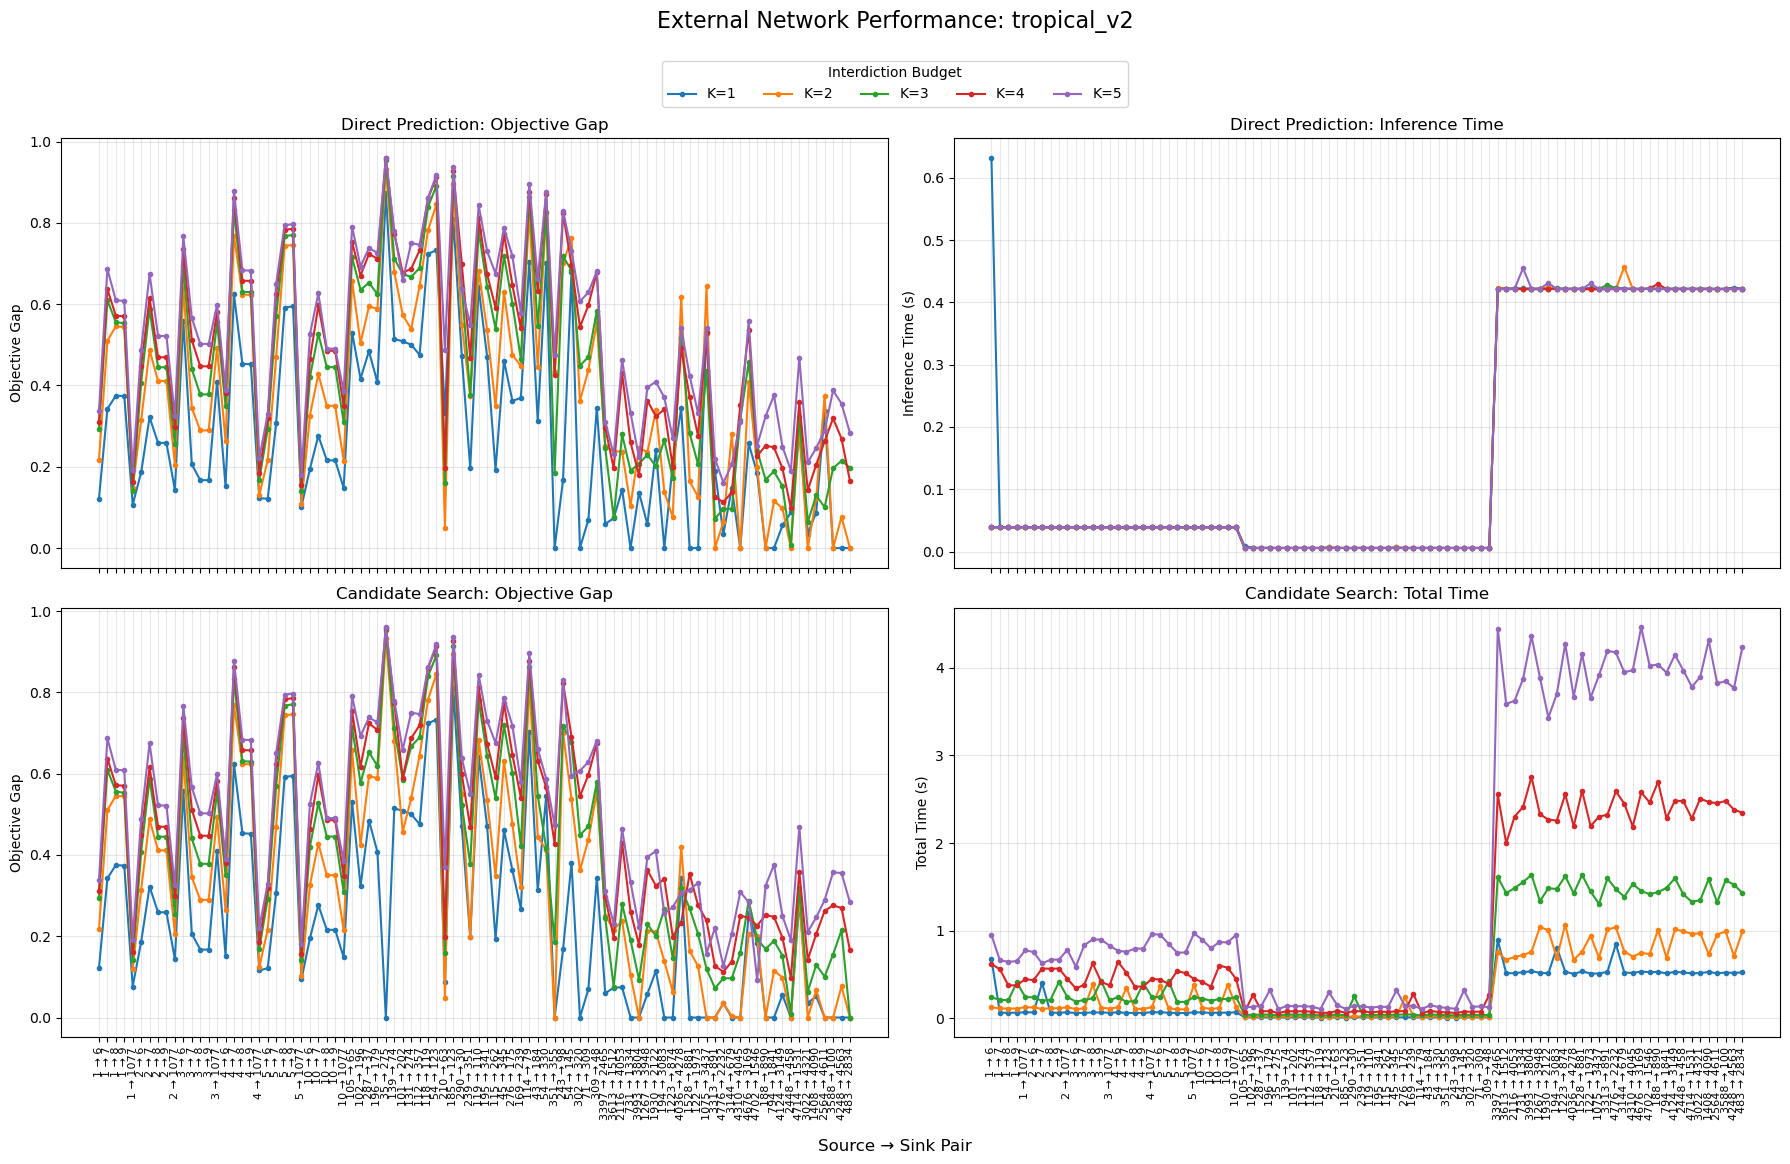

In [368]:
plot_external_metrics_by_model(df_all_eval, "tropical_v2")

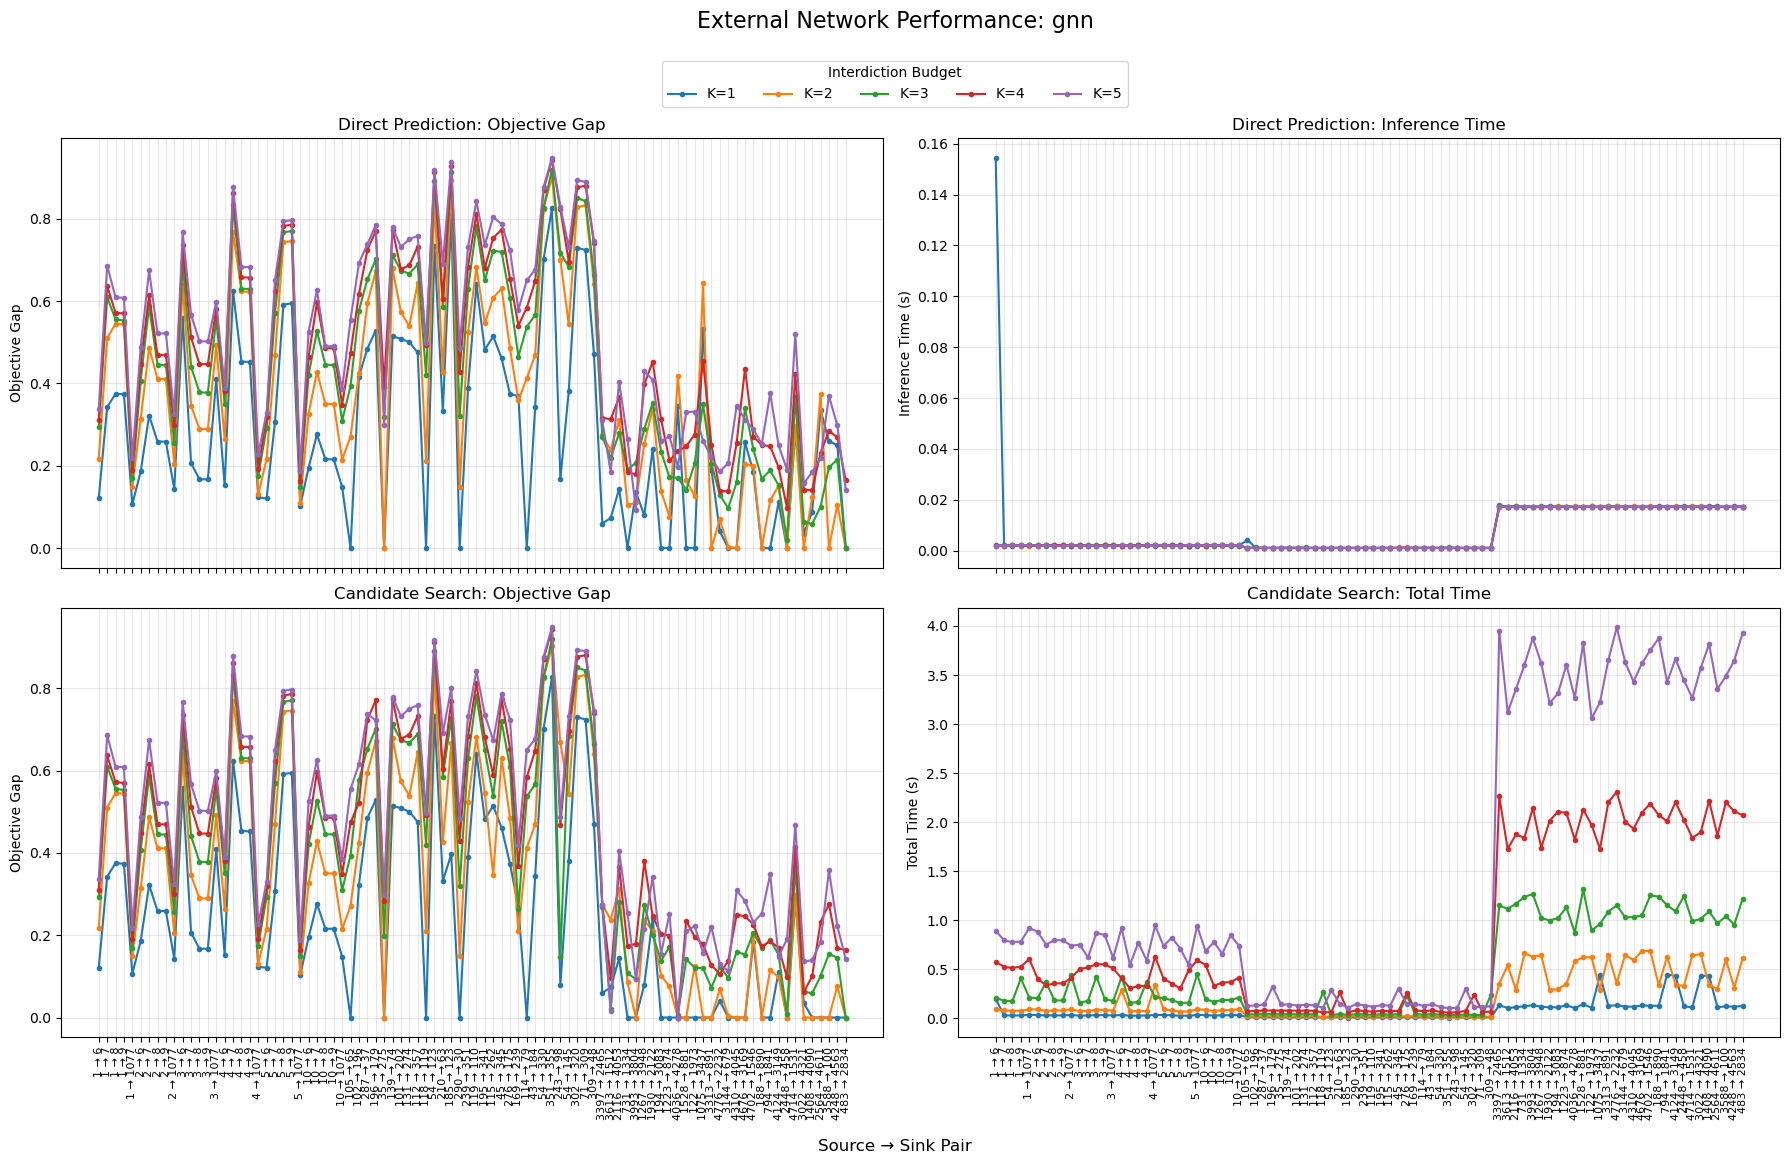

In [370]:
plot_external_metrics_by_model(df_all_eval, "gnn")

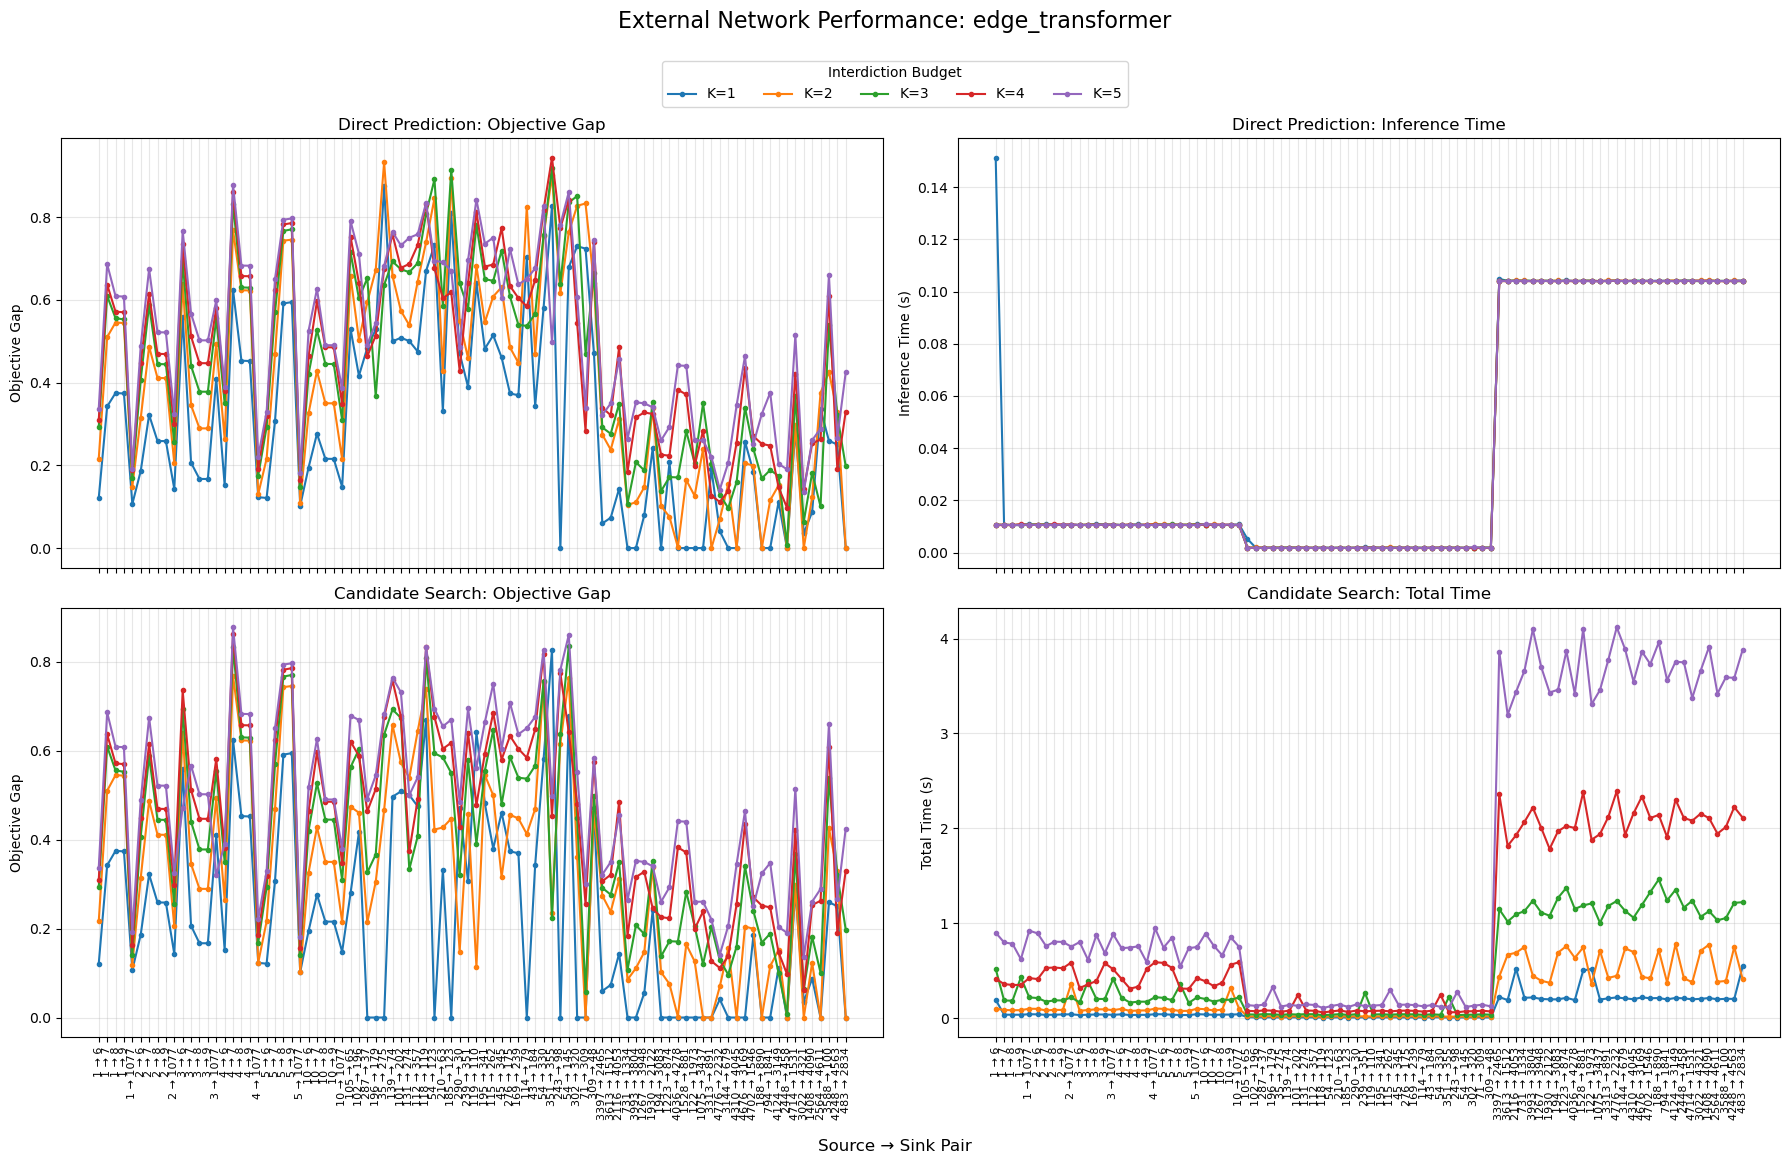

In [372]:
plot_external_metrics_by_model(df_all_eval, "edge_transformer")